In [1]:
import os
import re
import pickle
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import json
import glob
pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# Dataset Choice

In [2]:
csv_dir = '../results/2024/'

# Retrieve Results

In [3]:
csv_files = glob.glob(os.path.join(csv_dir, '*.csv'))
df = pd.DataFrame()
for csv_file in csv_files: 
    df = pd.concat([df, pd.read_csv(csv_file)])

In [4]:
df.sample(5)

,author,name,email,start_index,start_time,end_index,end_time,timezones
488486,3a63369c3598f5fb61650a5fd5398b96191794eda5d83d3042e8fe53c1245858,redgoose,scripter@me.com,1312,2019-12-09T20:00:10Z,1324,2019-12-10T18:32:18Z,"540,0,540,0,540"
7286,e9b6c2aa8850deac1cbfec2312d38b2c511fb71370c90a4e88eb7f5be4731cae,Dave Humphrey,uespnet@gmail.com,3861,2016-09-03T00:59:02Z,3863,2016-09-03T00:59:02Z,"0,-240,0"
292083,ffec1d5ee7ccb622605f69ac6e69f38aa64d544540731727ef3abaa31332c961,luca9294,luca9294@hotmail.it,78,2014-03-25T08:36:55Z,82,2014-03-25T14:55:58Z,"60,-420,60"
283614,5126279ee5fc92e8b0ed9484083535a76ea14ac19576705a8ccc844704886c02,Tom Spilman,tom@sickheadgames.com,627,2012-10-26T00:04:21Z,630,2012-10-26T20:03:53Z,"-300,-420,-300"
381483,abe0ee4e08ac083400bd3bbaa8b3e17814f37666df15bdfda4a81280a3010564,deploy.sh,NaN,2605,2019-04-25T16:40:23Z,2613,2019-04-26T13:17:35Z,"60,330,60"


In [5]:
print(f'size of df with bots: {len(df)}')
bot_pattern = re.compile(r'(?i)(?:\W|^)bot(?:\W|$)') 
bot_mask_email = df['email'].str.contains(bot_pattern, regex=True, na=False)
bot_mask_name = df['name'].str.contains(bot_pattern, regex=True, na=False)
df = df[~(bot_mask_email | bot_mask_name)]
print(f'size of df without bots: {len(df)}')

size of df with bots: 8794789
size of df without bots: 8726939


In [6]:
starts = pd.to_datetime(df['start_time'])
ends = pd.to_datetime(df['end_time'])
df['duration'] = (ends - starts).dt.total_seconds() / 3600

In [7]:
df['year'] = pd.to_datetime(df['start_time']).dt.year

In [8]:
author_info = df[['author', 'name', 'email']].drop_duplicates().set_index('author')

In [9]:
# Find rows where name is null
null_names = df[df['name'].isnull()]['author'].drop_duplicates().reset_index(drop=True)

# Print the count of rows with null names
print(f"Number of rows with null names: {len(null_names)}")

# Display the first few rows with null names
null_names.head() 

Number of rows with null names: 117


0    ce96579f73b05954327e08bdc3e2ba4a06e4fd5b0a2140f27ad5e4d56fafabbf
1    d343c2ff7a321d69064ffae180add8fb1a2fa900e4b651d20e99918f8cf8bc0e
2    2ed699b06ccdb539f8d85104743c0a4ac7a79ef3399987a0055cbc07ed2cfbd6
3    2f326d9af3ebd7a612dd82fce456906ff8dd5abb19268e7f90c3a6276f2702d2
4    32c10b9e11e8755e59c5deb848a6f3f7cb27ad490a4a3193633edc86d5a5c3e6
Name: author, dtype: object

In [10]:
author_counts = df['author'].value_counts()
top_5_authors = author_counts.head(5).index
author_info_bis = {}
for author in top_5_authors:
    author_rows = df[df['author'] == author]
    
    names = author_rows['name'].dropna()
    if len(names) > 0:
        name = names.iloc[0]
    else:
        name = "No name found" 
        
    emails = author_rows['email'].dropna() if 'email' in df.columns else []
    if len(emails) > 0:
        email = emails.iloc[0]
    else:
        email = "No email found"
    author_info_bis[author] = {"name": name, "email": email}

print("Top 5 most frequent authors with their names and emails:")
for author in top_5_authors:
    count = author_counts[author]
    info = author_info_bis[author]
    print(f"{author}: {count} occurrences - Name: {info['name']} - Email: {info['email']}")

Top 5 most frequent authors with their names and emails:
bf31a3c2592c2ebdc7dfd830d121c5ebeedb3ba1d3b1c171c4d9084fae1ce8c7: 6809 occurrences - Name: Seth Carter - Email: sundaymtn@gmail.com
7f678ff9fb24477f2f0e234aeb6a0478ab10d7fddd1123693646e9b5716d21ba: 5713 occurrences - Name: porthole-ascend-cinnamon - Email: porthole-ascend-cinnamon@protonmail.com
4017433d2b9259d0e66af1c13123e6e84104d0e6852921103ffc7cbecd993d32: 4157 occurrences - Name: Azure Static Web Apps - Email: opensource@microsoft.com
8d0a57a470462d3e322a3b3f77de3a16d546256b11d17506570a12bdca75fbcf: 3911 occurrences - Name: Google APIs - Email: googleapis-publisher@google.com
97ad6007776f1fdff5429a82f6ff531677ad64bb11b209a0ab520e73bee25dcb: 3799 occurrences - Name: Webster-Butterfly - Email: troymay0901@gmail.com


# Analysis

### Basic Stats

In [11]:
author_stats = pd.DataFrame({
    'total_windows': df.groupby('author').size(),
    'unique_patterns': df.groupby('author')['timezones'].apply(lambda x: len(set(tuple(tz) for tz in x))),
    'avg_changes_per_window': df.groupby('author')['timezones'].apply(lambda x: np.mean([len(tz) for tz in x])),
    'avg_window_durations': df.groupby('author')['duration'].mean()
})

**2min**

In [12]:
author_stats.sample(5)

,total_windows,unique_patterns,avg_changes_per_window,avg_window_durations
author,,,,
bb63dc2f0d59f8fcb8f16cd912753f6635a26e69be9e68715293a6bf288e8d52,1,1,12.0,0.000000
bac36dda71e5cf9ef7a19800d1e241c11677c3d8650295629be265e1d732a7b3,2,1,11.0,3.526111
8d56879ddb93bc615b29b65d40eec6cde50c3e1b7face6a9f0e9101e83b1a35a,1,1,19.0,5.712222
6ab771bcca57d101c1eb9f12d4e0d656ce4f5a0e5887d985ec88d8df3a2fc7f2,1,1,11.0,23.416111
8e4616e1f9d54880005287ed9c245351ee886a3b6d100cf042e9626fc0114c87,1,1,11.0,1.062778


In [13]:
max_stats = {
    'total_windows': author_stats['total_windows'].idxmax(),
    'unique_patterns': author_stats['unique_patterns'].idxmax(),
    'avg_changes_per_window': author_stats['avg_changes_per_window'].idxmax(),
    'avg_window_durations': author_stats['avg_window_durations'].idxmin()
}

max_authors = pd.DataFrame({
    'statistic': max_stats.keys(),
    'author_id': max_stats.values(),
    'name': [author_info.loc[author_id, 'name'] if author_id in author_info.index else 'Unknown' for author_id in max_stats.values()],
    'email': [author_info.loc[author_id, 'email'] if author_id in author_info.index else 'Unknown' for author_id in max_stats.values()],
    'value': [author_stats.loc[max_stats[stat], stat] for stat in max_stats.keys()]
})
# what date for unique pattern ? Old ?
max_authors

,statistic,author_id,name,email,value
0,total_windows,bf31a3c2592c2ebdc7dfd830d121c5ebeedb3ba1d3b1c171c4d9084fae1ce8c7,Seth Carter,sundaymtn@gmail.com,6809.000000
1,unique_patterns,7f678ff9fb24477f2f0e234aeb6a0478ab10d7fddd1123693646e9b5716d21ba,porthole-ascend-cinnamon,porthole-ascend-cinnamon@protonmail.com,5673.000000
2,avg_changes_per_window,fc23d9b6032c9dc846a3b7ee14072648b0f099b3405d932ff072712479372a12,Lupacescu Eduard,lupacescueduard@gmail.com,8855.378657
3,avg_window_durations,0001a58dc89c12e4ba2fdf35a0e0b68f875aca61f71178adce47c2020505d0f8,Rick Fillion,rick@centrix.ca,0.000000


### Effective window

In [14]:
avg_duration = author_stats['avg_window_durations']
smallest_duration_authors = pd.DataFrame({
    'author': avg_duration.sort_values().head(10).index,
    'avg_window_duration': avg_duration.sort_values().head(10).values
})
smallest_duration_authors = smallest_duration_authors.merge(
    author_info[['name', 'email']], 
    left_on='author', 
    right_index=True, 
    how='left'
)
print("Top 10 authors with shortest average window duration")
smallest_duration_authors

Top 10 authors with shortest average window duration


,author,avg_window_duration,name,email
0,4c842b607694b53a573b6bbf761f68a862d835ca80f0988c806ae906f06d6a49,0.0,syzbot,syzbot+67b2bd0e34f952d0321e@syzkaller.appspotmail.com
1,b710a330a4e8f761978b10a9af917e96490665ea30bc627ae34f7c01599eeb40,0.0,JSmith-BitFlipper,db.htam@gmail.com
2,f1dbe4e66b89fb3df08f391207f6864766a639656b9f598dfffacd2d190902f9,0.0,Boroondas Gupte (original patches by Aimee Linden),hg@boroon.dasgupta.ch
3,4c35c9d9866bb2693ed42104460b5b97fd9566613f81b2372448117115a30b53,0.0,Kouta Ooizumi,k-ooizumi@tnes.nec.co.jp
4,b869f98207f758367626225404751401ab36c204845d945b01eadeb926f7e70b,0.0,Konrad Adamczyk,konrad.adamczyk@cavium.com
5,b869d11086b7b3f2286230254a3181403198d8120a6991a29ba31d1e37df9e59,0.0,Cristiano,cristianocca@hotmail.com
6,f439e19f83a0c469ecb4b58afceaf343ddc02f3eaf00566fae22bbe93365b570,0.0,HanumathRao,hanu.ncr@gmail.com
7,fbb71974522be8e5e9e3420c46dda9c0189300baf089e9752172098c8b6ef083,0.0,Beno\xc3\xaet,benoit@gawab.com
8,e5832b888a44fcc86500aee0d2bbbbb7138cc309a57e4c40412c005647e4b167,0.0,lenios,lenios@free.fr
9,b7668e6dbcf9937ef0714c736a881f0f52aa76e88aa273ac5d555ee36a7d00eb,0.0,Botanic,admin@tempestintheaether.org


In [15]:
filtered_durations = avg_duration[(avg_duration >= 1) & (avg_duration < 2)]
filtered_duration_authors = pd.DataFrame({
    'author': filtered_durations.head(10).index,
    'avg_window_duration': filtered_durations.head(10).values
})
filtered_duration_authors = filtered_duration_authors.merge(
    author_info[['name', 'email']], 
    left_on='author', 
    right_index=True, 
    how='left'
)
print("Authors with average window duration between 1-2 hours:")
filtered_duration_authors

Authors with average window duration between 1-2 hours:


,author,avg_window_duration,name,email
0,0002b5c7d16d92cb43bc61b16aed68e10d7f633bddb29543d44e7acd96af2ca4,1.391389,samiraalsadatsaleh,112572181+samiraalsadatsaleh@users.noreply.github.com
1,00032c2b7ee8862c4b40cf64029772b08d0b783e6250fa0e73038d367f11a6a5,1.396389,mcseves,mcmseves@gmail.com
2,00052b1f9b9a84ae400e8eedcfd25ee140597dc1ff7e92531f6ea0b20d999ab0,1.203194,Thorin Stonehelm,ThorinStonehelm1@gmail.com
3,0007520bc9a799b326fe5e2b3550a4ebae76adb39e172caa47925bf3bdace7d9,1.300278,Glen Leatherman,gleather1969@gmail.com
4,000917c70fe1221257bc16fcb95da0105aae632d73149f5ac70032e911328534,1.520833,topritchett,38042502+topritchett@users.noreply.github.com
5,0009746d80f93fe5260e8b6f1820b2d0af1223e7487631f1eae546dbb33fc379,1.630833,Nopawit NITSAWANG,nopawit.n@ku.th
6,0009a975e170468278e15764e9ef856ac6afedec39c72f9e0b42c59fca5a067b,1.522639,Andreas Tande,andretan@stud.ntnu.no
7,000a96f22bd3ba154a6d22d0eed5dbd66ce9d98af1d2eca589c8a0cafb033943,1.948264,Lucas Satabin,2537737+satabin@users.noreply.github.com
8,000b20181110cd978c3fb93859f44138a29f98ea13569490d2d4a175af1f53f6,1.259444,Ronn Angelo Lee,rrlee@student.apc.edu.ph
9,000bb292cb6d721bf5c664fae5008d9df4f1ae17f338272c587e2ee862b864dd,1.098889,mayank suman,mayankcsmn@gmail.com


### Timezone Pattern

In [16]:
df.sample(2)

,author,name,email,start_index,start_time,end_index,end_time,timezones,duration,year
29068,3b794421c9e6704fee39dcc3ee335dff12a6342110efb3f4642a935140a01884,Seemion Seemionych,seelook@gmail.com,506,2011-11-10T09:35:03Z,511,2011-11-10T11:58:50Z,"60,0,60",2.396389,2011
72318,862070722ad87353d28cd21893a62104cd7137b3147f57dd739a5b7026d98d17,jshuang0520,31140138+jshuang0520@users.noreply.github.com,115,2017-10-11T13:53:01Z,149,2017-10-12T13:52:26Z,"-300,480,-300,480,-300,480,-300,480,-300,480,-300,480,-300,480",23.990278,2017


In [17]:
def timezone_to_tuple(tz_string):
    if isinstance(tz_string, str):
        return tuple(map(int, tz_string.split(',')))
    return tuple()

df['timezone_tuple'] = df['timezones'].apply(timezone_to_tuple)
pattern_author_counts = df.groupby('timezone_tuple')['author'].nunique().reset_index()
pattern_author_counts.columns = ['timezone_pattern', 'unique_authors']
pattern_author_counts = pattern_author_counts.sort_values(by='unique_authors', ascending=False)
pattern_counts = df['timezone_tuple'].value_counts().reset_index()
pattern_counts.columns = ['timezone_pattern', 'total_occurrences']
pattern_author_counts = pattern_author_counts.merge(pattern_counts, on='timezone_pattern')

total_authors = df['author'].nunique()
pattern_author_counts['percentage_of_total_authors'] = (pattern_author_counts['unique_authors'] / total_authors * 100).round(2)
pattern_author_counts['avg_window_per_author'] = (pattern_author_counts['total_occurrences'] / pattern_author_counts['unique_authors']).round(2)
pattern_author_counts['pattern_label'] = pattern_author_counts['timezone_pattern'].apply(lambda x: ', '.join(map(str, x)))

In [41]:
df.loc[df['timezone_tuple'].apply(lambda x: 350 in x)].sample(5)

,author,name,email,start_index,start_time,end_index,end_time,timezones,duration,year,timezone_tuple
5697,af41064cde0fd76c30fdf27bee29ecd3805afe4c6f56fb536c179cad016f0e44,Kishor Bhat,kishorbhat@gmail.com,650,2016-10-23T14:27:16Z,654,2016-10-24T13:34:59Z,"330,350,330,350",23.128611,2016,"(330, 350, 330, 350)"
124598,6a43ae0748749553aa8d9ec54da5a57f3f4b791eb29206b58bee62980a3fc564,Rithwik,0rithwik@gmail.com,21,2016-03-11T13:12:15Z,24,2016-03-12T09:46:34Z,"330,350,330,350",20.571944,2016,"(330, 350, 330, 350)"
100001,fa7406ed522d284921ae2fd9561f9c487c028b0f3495e499eecdd7febcb07ea4,Saurabh Kumar,me+github@saurabh-kumar.com,182,2015-02-08T06:35:32Z,196,2015-02-08T16:32:30Z,"330,350,330,350,330,350",9.949444,2015,"(330, 350, 330, 350, 330, 350)"
175983,13d5860810b762c0c2be8ba22080101e8d03cf3364daa520e7c527ec5897d4df,harie_22,harie20202@gmail.com,201,2022-08-11T09:59:06Z,317,2022-08-12T09:45:31Z,"350,330,350,330,350,330,350",23.773611,2022,"(350, 330, 350, 330, 350, 330, 350)"
261399,d31b2c260098cadecb9921cade0814299af88b4890e068d6aeed4d3dea9677bc,nikramakrishnan,ramakrishnan.nikhil@gmail.com,212,2018-06-12T11:34:29Z,221,2018-06-13T08:12:07Z,"330,350,330,350,330,350,330",20.627222,2018,"(330, 350, 330, 350, 330, 350, 330)"


**2min**

In [18]:
print(f"Total unique authors in dataset: {total_authors}")
print("Top timezone patterns by number of unique authors:")
pattern_author_counts.head(5)

Total unique authors in dataset: 1170777
Top timezone patterns by number of unique authors:


,timezone_pattern,unique_authors,total_occurrences,percentage_of_total_authors,avg_window_per_author,pattern_label
0,"(120, 0, 120)",98416,321974,8.41,3.27,"120, 0, 120"
1,"(60, 0, 60)",96096,286717,8.21,2.98,"60, 0, 60"
2,"(-300, 0, -300)",51018,135642,4.36,2.66,"-300, 0, -300"
3,"(0, 60, 0)",49568,126894,4.23,2.56,"0, 60, 0"
4,"(0, 120, 0)",47303,131692,4.04,2.78,"0, 120, 0"


In [19]:
long_patterns = pattern_author_counts.loc[pattern_author_counts['timezone_pattern'].apply(lambda x: len(set(x)) > 2)]
long_patterns_sorted = long_patterns.sort_values(by='total_occurrences', ascending=False)
print(f"Found {len(long_patterns_sorted)} patterns with more than 2 distinct timezone offsets")
print("Top patterns sorted by total occurrences:")
long_patterns_sorted.head(5)

Found 297196 patterns with more than 2 distinct timezone offsets
Top patterns sorted by total occurrences:


,timezone_pattern,unique_authors,total_occurrences,percentage_of_total_authors,avg_window_per_author,pattern_label
497,"(-420, 180, 120)",1132,1195,0.10,1.06,"-420, 180, 120"
522,"(-420, 120, 180)",1068,1139,0.09,1.07,"-420, 120, 180"
673,"(60, 0, 120)",732,862,0.06,1.18,"60, 0, 120"
751,"(-240, 0, -420)",624,840,0.05,1.35,"-240, 0, -420"
646,"(-420, -180, -240)",789,825,0.07,1.05,"-420, -180, -240"


**4min**

### Graphic

In [20]:
def graphic(ds, title):
    plt.figure(figsize=(18, 8))
    x = np.arange(len(ds))
    width = 0.35
    ax1 = plt.gca()
    def format_with_commas(value):
        return f'{value:,}'
    bars1 = ax1.bar(x - width/2, ds['unique_authors'], width, 
                    label='Unique Authors', color='#3274A1')
    for bar in bars1:
        height = bar.get_height()
        ax1.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')
    ax2 = ax1.twinx()
    bars2 = ax2.bar(x + width/2, ds['total_occurrences'], width, 
                    label='Total Occurrences', color='#E15759')
    for bar in bars2:
        height = bar.get_height()
        ax2.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')
    ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: format_with_commas(int(x))))
    ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: format_with_commas(int(x))))

    ax1.set_xlabel('Timezone Pattern', fontsize=12)
    ax1.set_ylabel('Unique Authors', fontsize=12, color='#3274A1')
    ax2.set_ylabel('Total Occurrences', fontsize=12, color='#E15759')
    plt.title(title, fontsize=14)
    ax1.set_xticks(x)
    ax1.set_xticklabels(ds['pattern_label'], rotation=45, ha='right')
    ax1.tick_params(axis='y', colors='#3274A1')
    ax2.tick_params(axis='y', colors='#E15759')
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
    ax1.grid(True, axis='y', linestyle='--', alpha=0.7)
    stats_text = (f"Total patterns: {format_with_commas(len(pattern_author_counts))}\n"
                f"Total unique authors: {format_with_commas(total_authors)}\n"
                f"Top pattern covers: {ds['percentage_of_total_authors'].iloc[0]:.1f}% of all authors")
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.4)
    plt.figtext(0.75, 0.8, stats_text, fontsize=10, bbox=props)
    plt.tight_layout()
    plt.show()

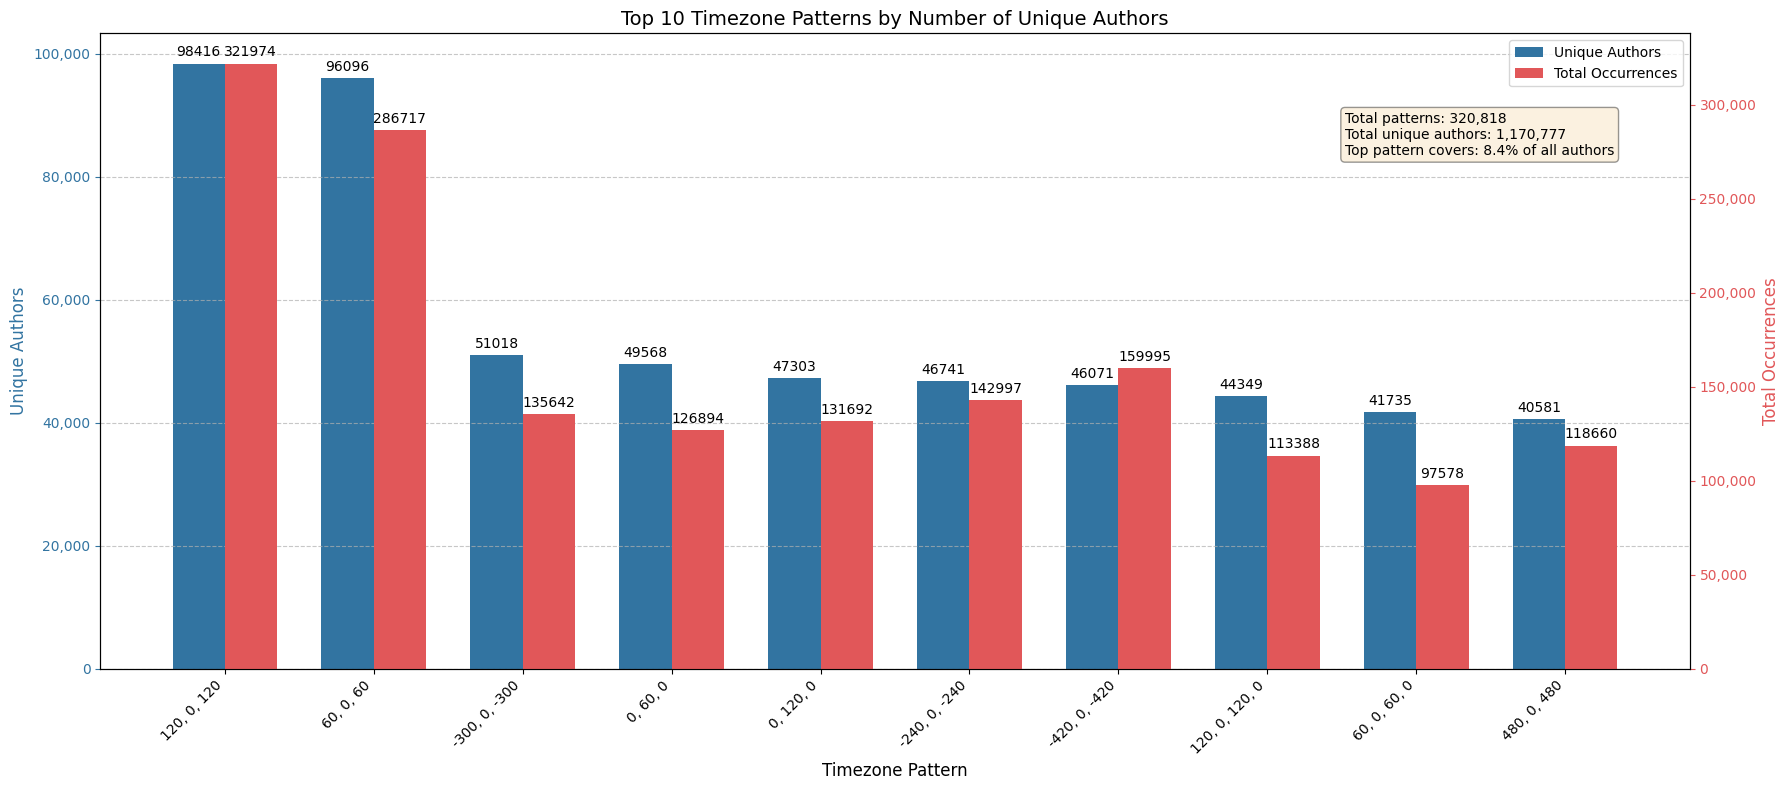

In [21]:
top_patterns = pattern_author_counts.head(10).copy()
graphic(top_patterns, 'Top 10 Timezone Patterns by Number of Unique Authors')

## Without UTC

In [22]:
df_without_utc = pattern_author_counts.loc[pattern_author_counts['timezone_pattern'].apply(lambda x: 0 not in x)]

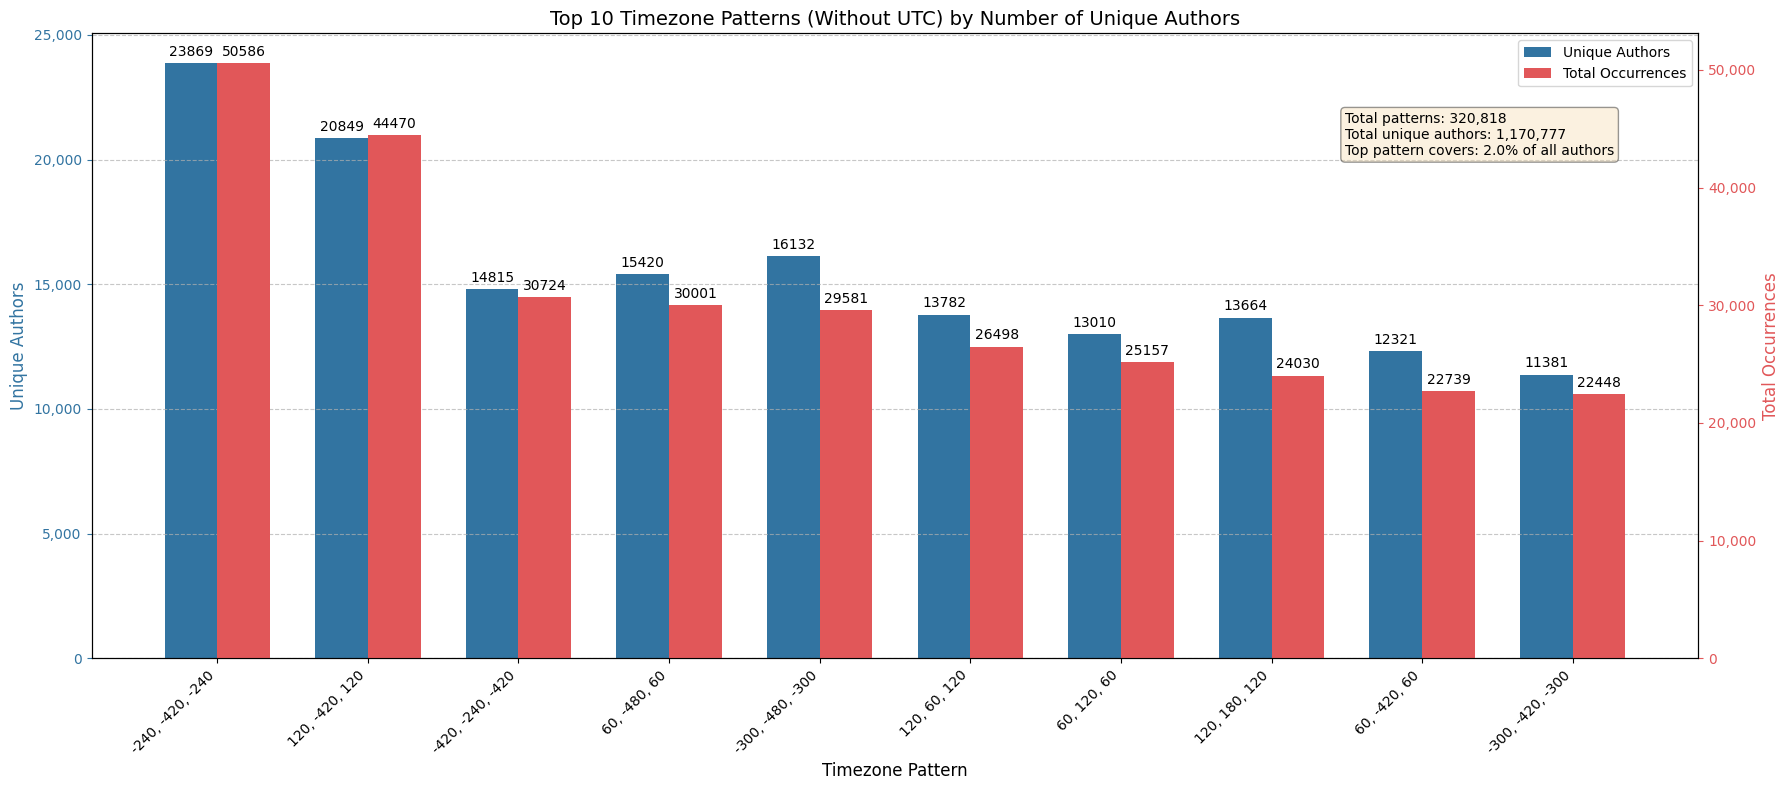

In [23]:
graphic(df_without_utc.sort_values(by=['total_occurrences'], ascending=False).head(10), 'Top 10 Timezone Patterns (Without UTC) by Number of Unique Authors')

- (-240, -420, -240) -> Summer Time (NY, LA, NY)
- (120, -420, 120) -> Summer Time (Europe, LA, Europe)

## Timezones that are not %60

In [24]:
df_only_partial = pattern_author_counts.loc[pattern_author_counts['timezone_pattern'].apply(lambda x: any(element % 60 != 0 for element in x))]

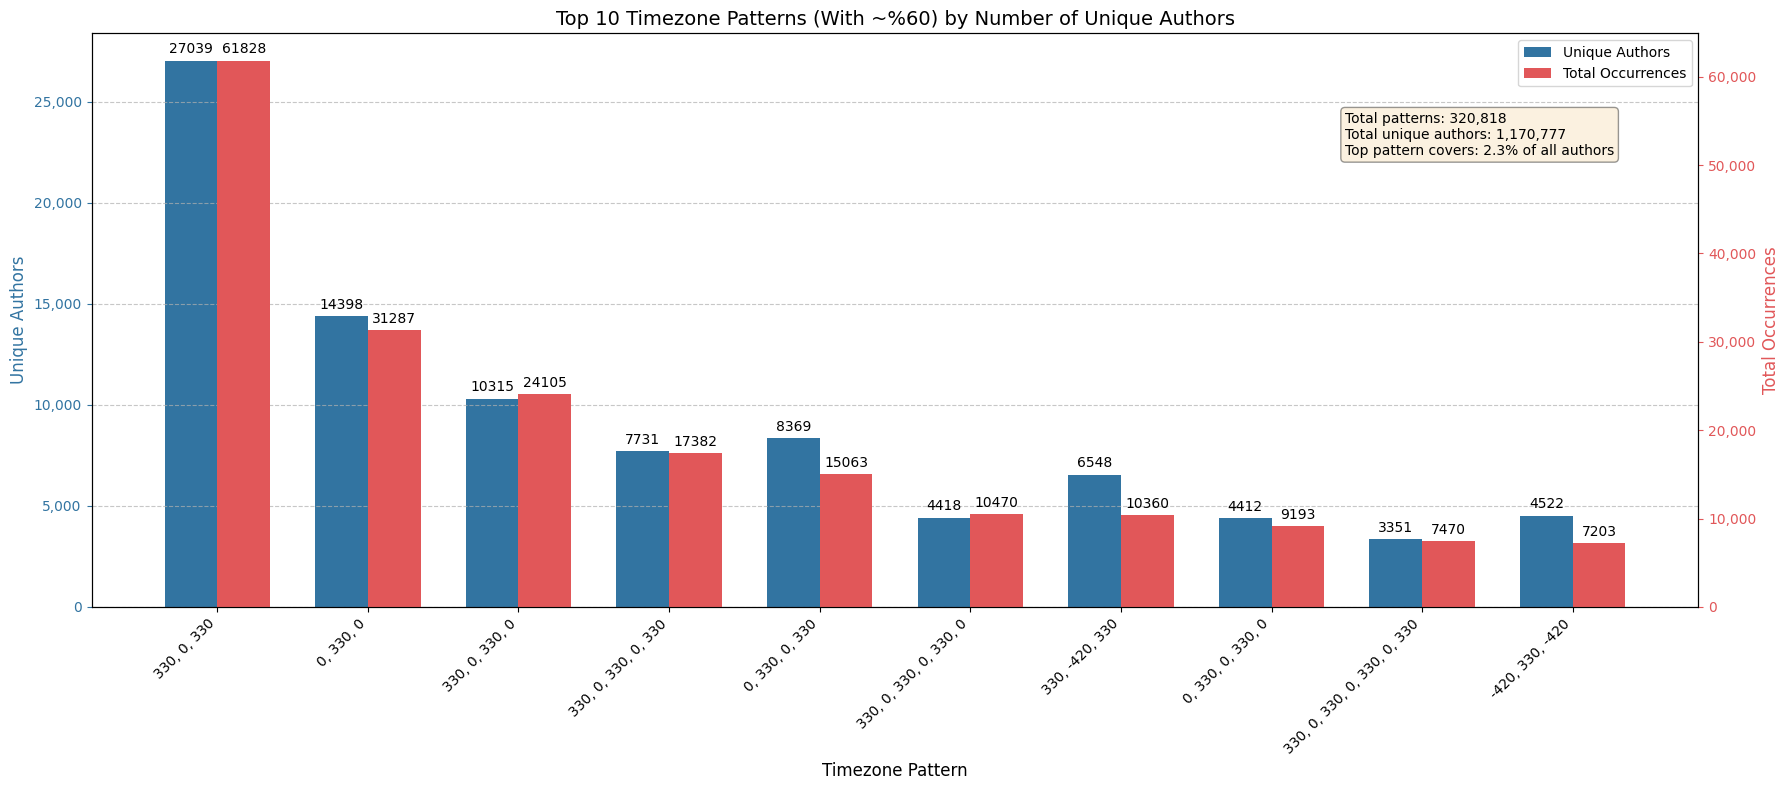

In [25]:
graphic(df_only_partial.sort_values(by=['total_occurrences'], ascending=False).head(10), 'Top 10 Timezone Patterns (With ~%60) by Number of Unique Authors')

## Patterns without UTC and with non 60min timezone

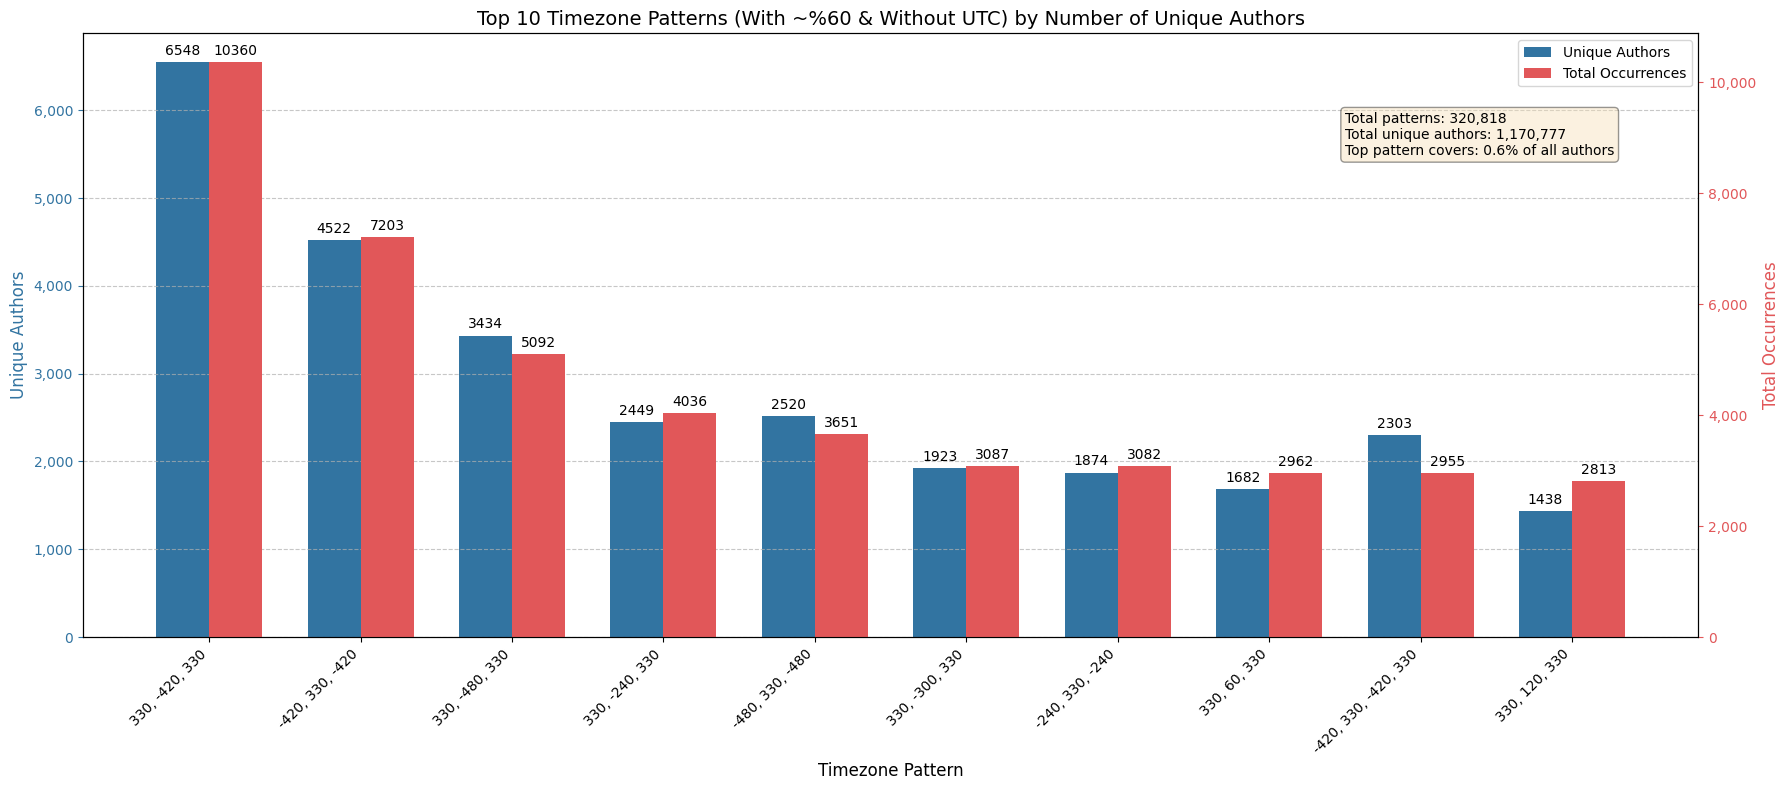

In [26]:
df_almost_exotic = df_without_utc.loc[df_without_utc['timezone_pattern'].apply(lambda x: any(timezone % 60 != 0 for timezone in x))]
graphic(df_almost_exotic.sort_values(by=['total_occurrences'], ascending=False).head(10), 'Top 10 Timezone Patterns (With ~%60 & Without UTC) by Number of Unique Authors')

## Patterns without UTC and with non 30min timezone

In [27]:
df_exotic = df_without_utc.loc[df_without_utc['timezone_pattern'].apply(lambda x: any((timezone % 30 != 0 and timezone != 1) for timezone in x))]

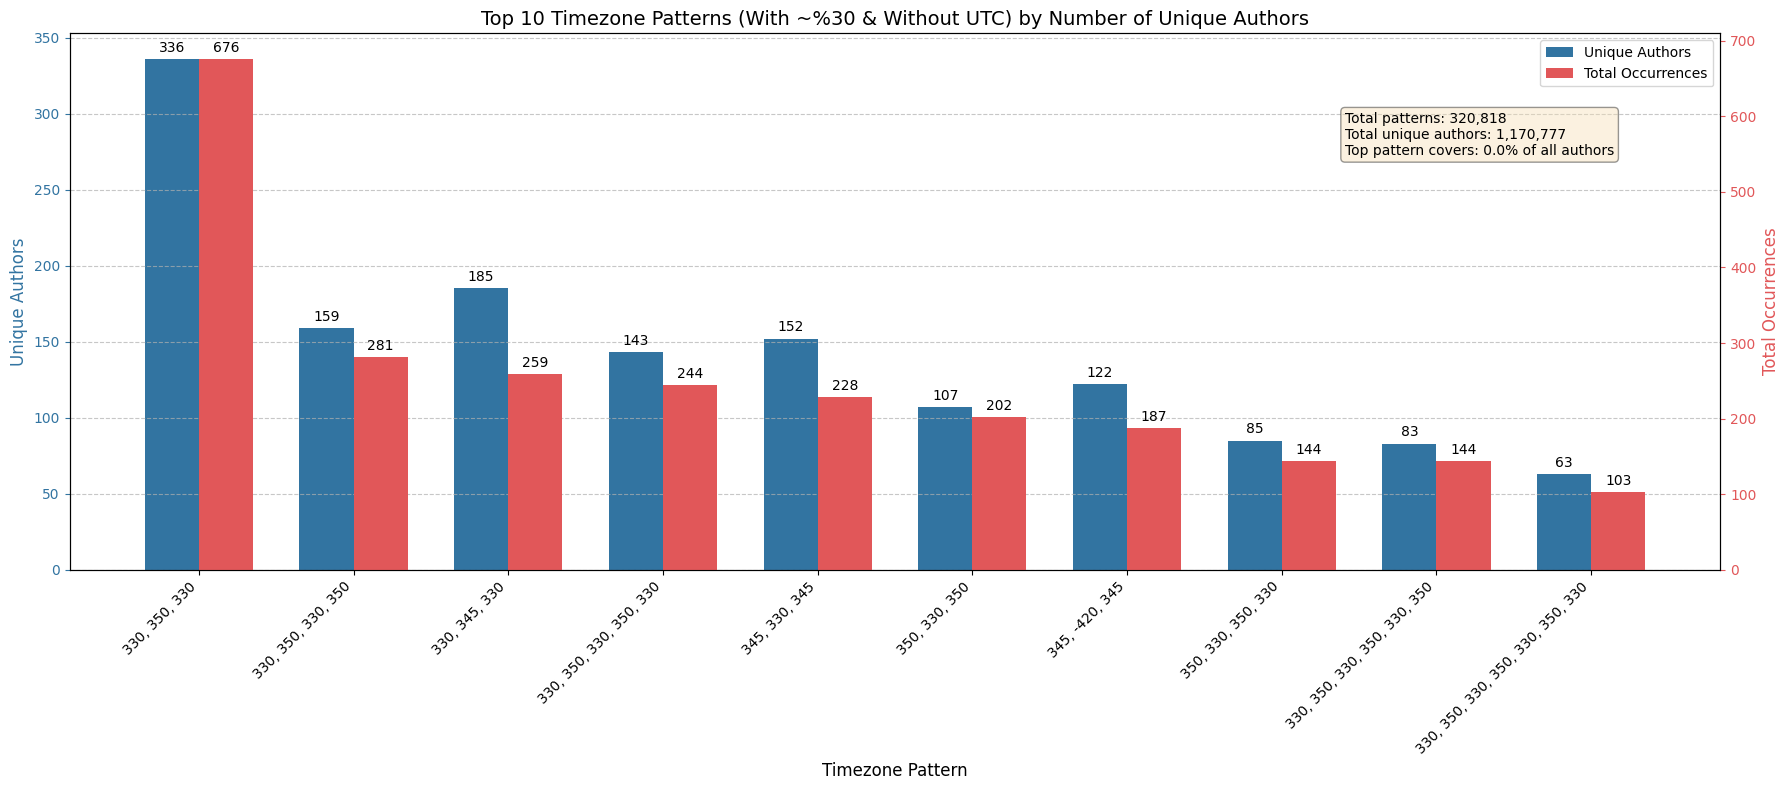

In [28]:
graphic(df_exotic.sort_values(by=['total_occurrences'], ascending=False).head(10), 'Top 10 Timezone Patterns (With ~%30 & Without UTC) by Number of Unique Authors')

- (330, 345. 330) -> India, Nepal, India

In [50]:
df_350 = df.loc[df['timezone_tuple'].apply(lambda x: 350 in x)]
df_350['start_time'].sort_values(ascending=False).head()

446073    2024-10-09T04:43:35Z
266412    2024-09-29T13:49:19Z
446072    2024-08-04T12:19:19Z
446071    2024-08-01T16:29:49Z
446070    2024-07-31T17:28:38Z
Name: start_time, dtype: object

In [29]:
def contains_both_offsets(pattern):
    if isinstance(pattern, tuple):
        return 330 in pattern and 350 in pattern
    return False

authors_330_350 = df[df['timezone_tuple'].apply(contains_both_offsets)]
unique_authors = authors_330_350[['author', 'name', 'email']].drop_duplicates().reset_index(drop=True)

print(f"Found {len(unique_authors)} unique authors with patterns containing both 330 and 350 timezone offsets:")
unique_authors.head()

Found 654 unique authors with patterns containing both 330 and 350 timezone offsets:


,author,name,email
0,cb95ced0e6d2f343e5d7b6f267c3c404ac4e04250ab01bfbd484b87433ad1db4,Joshua Schultz,joshuamschultz@gmail.com
1,cbdb67ac214414af490f19d2503ae2d44bed63ea99f7629fd3e8b3a86fef1aa8,Barath Prathosh M,barathprathosh@groupteampro.com
2,ccecf87fa503c5a6ef74cdb7115707419b42367fd96bb0a9f8eb5e76745187b8,Praveen Chinta,praveen.chinta@turner.com
3,cd774bbdf937e293b9910b9ebd435459fcfc346bc506e5be24f1031f6ead924b,Varun Kruthiventi,saivarunk@gmail.com
4,cda969fcd04d66fb0348fb2958615167f63e175498cd4c3dd70e671e644eecd8,rihbyne,rihen234@gmail.com


## Amount of patterns through years
It goes from 1776 to 2106, we display only those between 1995 and 2024.

In [30]:
pattern_by_year = df['year'][(df['year'] >= 1995) & (df['year'] <= 2024)].value_counts().sort_index()

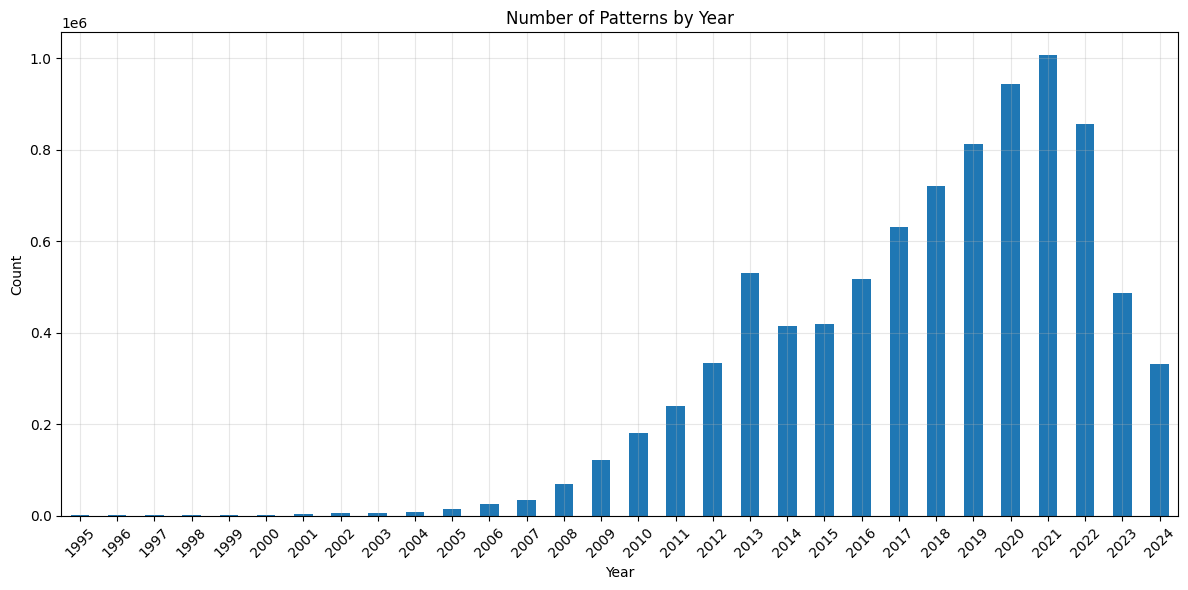

In [31]:
plt.figure(figsize=(12, 6))
pattern_by_year.plot(kind='bar')
plt.title('Number of Patterns by Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
df_commits_year = pd.read_csv('../results/commit_year_counts.csv')

In [33]:
df_commits_year.sample(5)

,year,count
742,2650,365
675,2583,365
580,2488,366
495,2403,365
294,2202,366


In [34]:
filtered_df = df_commits_year.sort_values(by='year').query('year >= 1995 and year <= 2024')
filtered_df.sample(5)

,year,count
106,2014,148131639
92,2000,6877231
93,2001,18584340
111,2019,428337216
99,2007,32508540


<Figure size 1200x600 with 0 Axes>

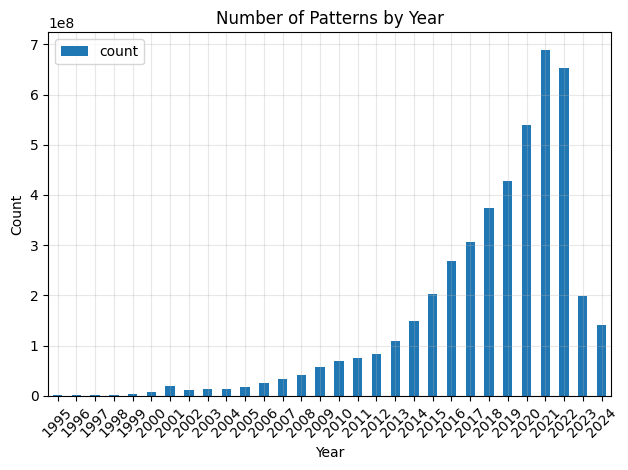

In [35]:
plt.figure(figsize=(12, 6))
filtered_df.plot(kind='bar', x='year', y='count')
plt.title('Number of Patterns by Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

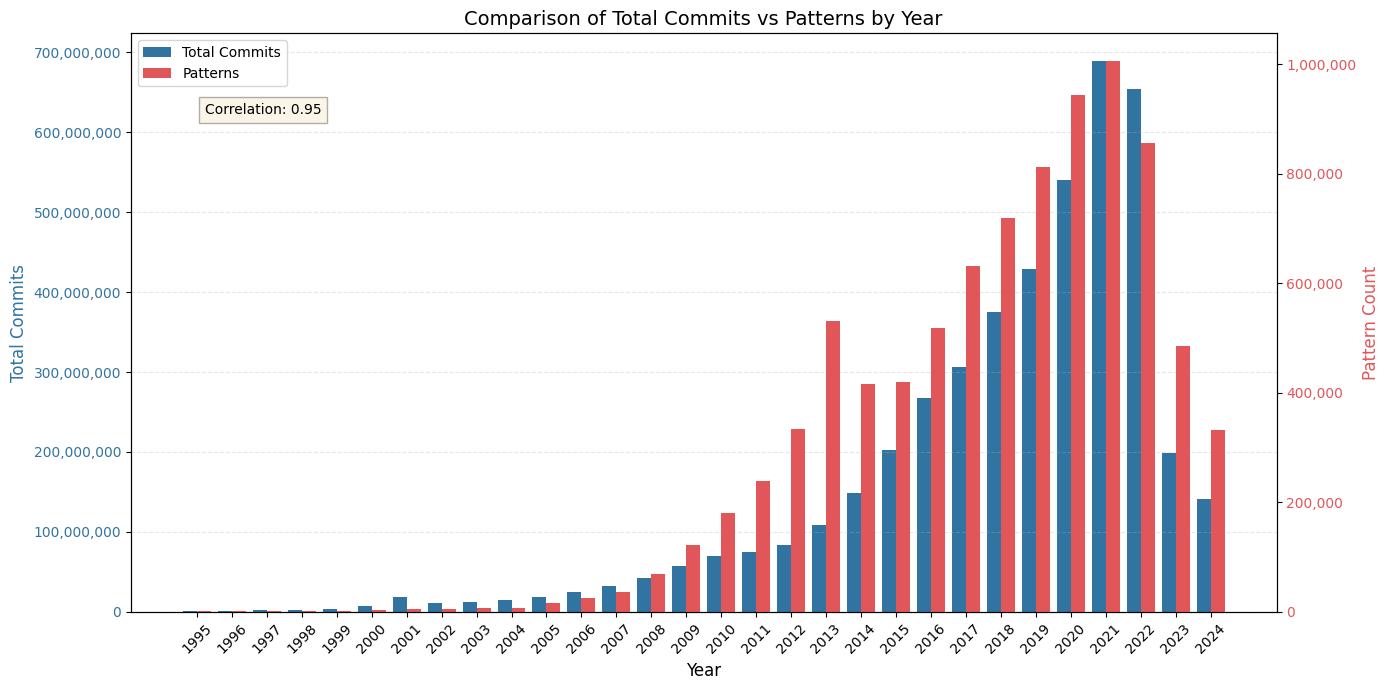

In [36]:
plt.figure(figsize=(14, 7))
all_years = sorted(set(filtered_df['year']).union(set(pattern_by_year.index)))
x = np.arange(len(all_years))
def format_with_commas(value, pos):
    return f'{int(value):,}'
ax1 = plt.gca()
filtered_values = [filtered_df[filtered_df['year'] == year]['count'].values[0] 
                  if year in filtered_df['year'].values else 0 
                  for year in all_years]
bars1 = ax1.bar(x - 0.2, filtered_values, 0.4, color='#3274A1', label='Total Commits')
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(format_with_commas))
ax1.set_ylabel('Total Commits', color='#3274A1', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#3274A1')
ax2 = ax1.twinx()
pattern_values = [pattern_by_year.loc[year] if year in pattern_by_year.index else 0 
                 for year in all_years]
bars2 = ax2.bar(x + 0.2, pattern_values, 0.4, color='#E15759', label='Patterns')
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(format_with_commas))
ax2.set_ylabel('Pattern Count', color='#E15759', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#E15759')

plt.title('Comparison of Total Commits vs Patterns by Year', fontsize=14)
ax1.set_xlabel('Year', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(all_years, rotation=45)
ax1.grid(True, axis='y', linestyle='--', alpha=0.3)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

if len(filtered_values) == len(pattern_values):
    correlation = np.corrcoef(filtered_values, pattern_values)[0, 1]
    corr_text = f'Correlation: {correlation:.2f}'
    plt.figtext(0.15, 0.83, corr_text, fontsize=10, 
               bbox=dict(facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.show()

# Sandbox

In [37]:
author_300 = df.loc[df['timezone_tuple'].apply(lambda pattern: 300 in pattern), ['author', 'name', 'email', 'timezone_tuple']].drop_duplicates().sort_index(inplace=False)
print(len(author_300))
author_300.sample(5)

44799


,author,name,email,timezone_tuple
15698,af8859decbcfdb428abdc06f357c297567a346afe8f1efff2919f6499a29f6e3,tyuhgce,tyuhgce@gmail.com,"(360, 300, 360)"
53173,2daa5a85ae50e4f2b8e257b20238ef733b4a2fdd2b597d200fed1cbcbc95d677,Star-325,starwong325@gmail.com,"(120, 330, 120, 300, 330, 60, 0, 120)"
211656,5d9616356ecbe1cd755297e8500f5db64355f2737f6237803ea642342bd4394b,APF Studio,35601097+APF-Studio@users.noreply.github.com,"(360, 300, 360)"
262772,a8b60f9d7b3fda25c3b25ac16deed5d5b85e5d14d5a17ad8539954ca69508524,CodeCraze25,juanhub25@outlook.com,"(-300, 300, -420, 120, -420)"
169647,fc7b900829cb7f564f7391a12813dde0b2f249e11cf924035c078134b757bf91,FedorMutovin,59576958+FedorMutovin@users.noreply.github.com,"(300, -300, 300)"


In [38]:
bot_name = df.loc[df['name'].notna() & df['name'].str.contains('bot', case=False)]
print(len(bot_name))
bot_name.sample(5)

26708


,author,name,email,start_index,start_time,end_index,end_time,timezones,duration,year,timezone_tuple
164131,225cdc6cebd6f8f4e0c95a17ce210ee7f017a9d6c0e2e732d4d0c6e84a7af52a,Eric Botcazou,ebotcazou@libertysurf.fr,459,2003-09-27T17:18:25Z,463,2003-09-27T17:23:23Z,"0,120,0,120",0.082778,2003,"(0, 120, 0, 120)"
244233,41a0b53bda3647f36ca00b21914f8a9599eeb1859071557909a06c5d051b5aad,Faidon Liambotis,faidon@wikimedia.org,3100,2015-10-16T11:33:10Z,3114,2015-10-16T13:09:00Z,"0,-240,0,-240",1.597222,2015,"(0, -240, 0, -240)"
216242,6d272cd68f1b95984a08064948f17890cec8ae713f4095ff14f161ff3900ea4b,LaunchDarklyReleaseBot,launchdarklyreleasebot@launchdarkly.com,1646,2024-03-04T20:15:36Z,1649,2024-03-04T20:20:27Z,"0,-480,0",0.080833,2024,"(0, -480, 0)"
32623,1e35211b876ac08cf1d6dc3bf0a5ac3abb6c3b3446379ad988286e10fabe4a4f,syzbot,syzbot+21456e3ef58cde16e0fa@syzkaller.appspotmail.com,0,2019-05-31T14:58:06Z,2,2019-05-31T14:58:06Z,"1020,-420,1020",0.000000,2019,"(1020, -420, 1020)"
65241,5950ecd3fb58c1341fb290755dccd7800bf15232b5d2f0650b4e27b3dd35af49,MassiveBattlebotsFan,62067763+MassiveBattlebotsFan@users.noreply.github.com,47,2021-05-07T17:43:37Z,56,2021-05-08T05:36:58Z,"-300,0,-300,0,-300,0,-300",11.889167,2021,"(-300, 0, -300, 0, -300, 0, -300)"
